# Radio imaging from visibilities: a simulated tutorial

This tutorial takes a simulated ALMA-like observation from visibilities to an image: build a `ComplexVisData`, set up the calibration nuisances, start from CLEAN, then fit a pixel `Image` and compare it with the truth. Everything is synthetic and seeded, so it runs anywhere in about a minute on a laptop CPU. For real data, replace the simulation with `ComplexVisData.read_ms`; the [radio interferometry guide](radio_interferometry.md) and the [CLEAN guide](radio_clean.md) document each piece.

In [1]:
import warnings

warnings.filterwarnings("ignore", category=SyntaxWarning)  # a docstring in a dependency
warnings.filterwarnings("ignore", message="IProgress")

In [2]:
import jax
import matplotlib.pyplot as plt
import numpy as onp
import numpyro.distributions as dist
from matplotlib.colors import PowerNorm

from virgil import CalibrationNuisance, ComplexVisData, Image, fit, scenes
from virgil._geometry import image_visibilities
from virgil.imaging import MaxEntropy
from virgil.radio_clean import clean, restore

jax.config.update("jax_enable_x64", True)  # the Toeplitz χ² needs float64

## Simulated data

The truth is a 65 × 65 image of 4 mas pixels: an inclined ring of radius 60 mas holding 0.8 Jy, and a compact clump to its north-east holding 0.2 Jy. The observation tracks 300 random baselines for six hours (east and north components each log-uniform between 100 m and 10 km) at 1.3 mm from a southern site, giving 60,000 uv points. The visibilities are the exact transform of the truth plus Gaussian noise of 0.05 Jy per real and imaginary part.

In [3]:
N, S, SIG = 65, 4.0, 0.05  # pixels, mas per pixel, Jy per real/imaginary part
truth = onp.asarray(0.8 * scenes.ring(N, S, 60, 10, inc_deg=50, pa_deg=40) + 0.2 * scenes.gaussian_blob(N, S, 6, dra=90, ddec=60))
rng = onp.random.default_rng(1)
bl = onp.exp(rng.uniform(onp.log(100), onp.log(1e4), (300, 2))) * rng.choice([-1, 1], (300, 2))  # east, north (m)
H, dec, lat = onp.deg2rad(onp.linspace(-45, 45, 200)), onp.deg2rad(-37), onp.deg2rad(-23)
u = ((bl[:, :1] * onp.cos(H) - bl[:, 1:] * onp.sin(lat) * onp.sin(H)) / 1.3e-3).ravel()
v = ((bl[:, :1] * onp.sin(dec) * onp.sin(H) + bl[:, 1:] * (onp.sin(lat) * onp.sin(dec) * onp.cos(H) + onp.cos(lat) * onp.cos(dec))) / 1.3e-3).ravel()
vis = onp.asarray(image_visibilities(truth, u, v, S, ft="dft")) + SIG * (rng.normal(size=u.size) + 1j * rng.normal(size=u.size))

In [4]:
data = ComplexVisData.from_arrays(u, v, vis, 1 / SIG**2, 230e9)  # u, v in wavelengths; weight = 1/σ²
print(f"{len(data)} visibilities, longest baseline {onp.hypot(u, v).max() / 1e6:.1f} Mλ")

60000 visibilities, longest baseline 9.9 Mλ


## Calibration nuisances

`CalibrationNuisance` configures what is fitted besides the sky. Here there is one observation with known errors, so only the total flux `cal.flux` is fitted: no gains, offsets, spectral index or error scales.

In [5]:
nuis = CalibrationNuisance(data, ref_obs=0, alpha=False, offsets=False, sigmas=False)
priors = nuis.priors()  # just cal.flux

## A CLEAN start

`radio_clean.clean` gives a first image and its restoring beam (`fit_beam` fits the beam to the dirty beam's core). **Known problem ([virgil#551](https://github.com/benjaminpope/virgil/issues/551)):** on this dataset (dynamic range about 1000) `clean` diverges if it runs long: the peak residual rises inside a minor cycle and the model flux reaches 10³ Jy by 12,000 iterations, so a lower `threshold` or a larger `niter` gives a nonsense model. The cell below stops at 1000 iterations, before that happens, and does not reach the 3σ threshold it asks for. We compare reconstructions through that beam, which is what a perfect image would look like at this resolution.

In [6]:
sigma_img = 1 / onp.sqrt(onp.sum(onp.asarray(data.weight)))  # thermal noise of the natural-weighted image
res = clean(data, N, S, deconvolver="hogbom", niter=1000, threshold=3 * sigma_img, usemask="auto-multithresh")
print(f"CLEAN stopped on '{res.stop}' after {res.iterations} iterations; beam {res.beam[0]:.0f} x {res.beam[1]:.0f} mas")

CLEAN stopped on 'niter' after 1000 iterations; beam 49 x 46 mas


## Fitting an Image

The scene is a pixel `Image` (the pixels are `softmax(log_brightness)`, scaled by `cal.flux`), started from the CLEAN model. `MaxEntropy` regularizes it weakly. `chi2="auto"` is the default: because the scene is one fixed `Image`, with no antenna gains, offsets or fitted spectral index, in float64, with enough points per pixel, `fit` evaluates the exact Toeplitz form of χ² (a few FFTs of the image instead of a transform of 60,000 points), and `info["likelihood_forms"]` reports which form ran.

In [7]:
scene = lambda values: Image(values["log_brightness"], pixel_scale_mas=S)
start = onp.clip(res.model, 0, None) / onp.clip(res.model, 0, None).sum()
init = nuis.defaults()
init["log_brightness"] = onp.log(start + 1e-4 * start.max())
init["cal.flux"] = float(res.model.sum())
priors["log_brightness"] = dist.Normal(0.0, 3.0)

term = data.term(scene, nuis, chi2="auto")
result = fit(lambda **values: scene(values), priors, (), likelihoods=[term], regularizers=[MaxEntropy(1e3)],
             init=init, method="lbfgs", max_steps=5000)
print(result.info["likelihood_forms"], f"converged={result.info['converged']} in {result.info['steps']} steps")

['toeplitz'] converged=True in 3722 steps


## The image against the truth

All panels are seen through the CLEAN beam, in Jy/beam. The last two are the CLEAN and fitted images minus the truth, on the same scale: signed residuals, with no uncertainties attached.

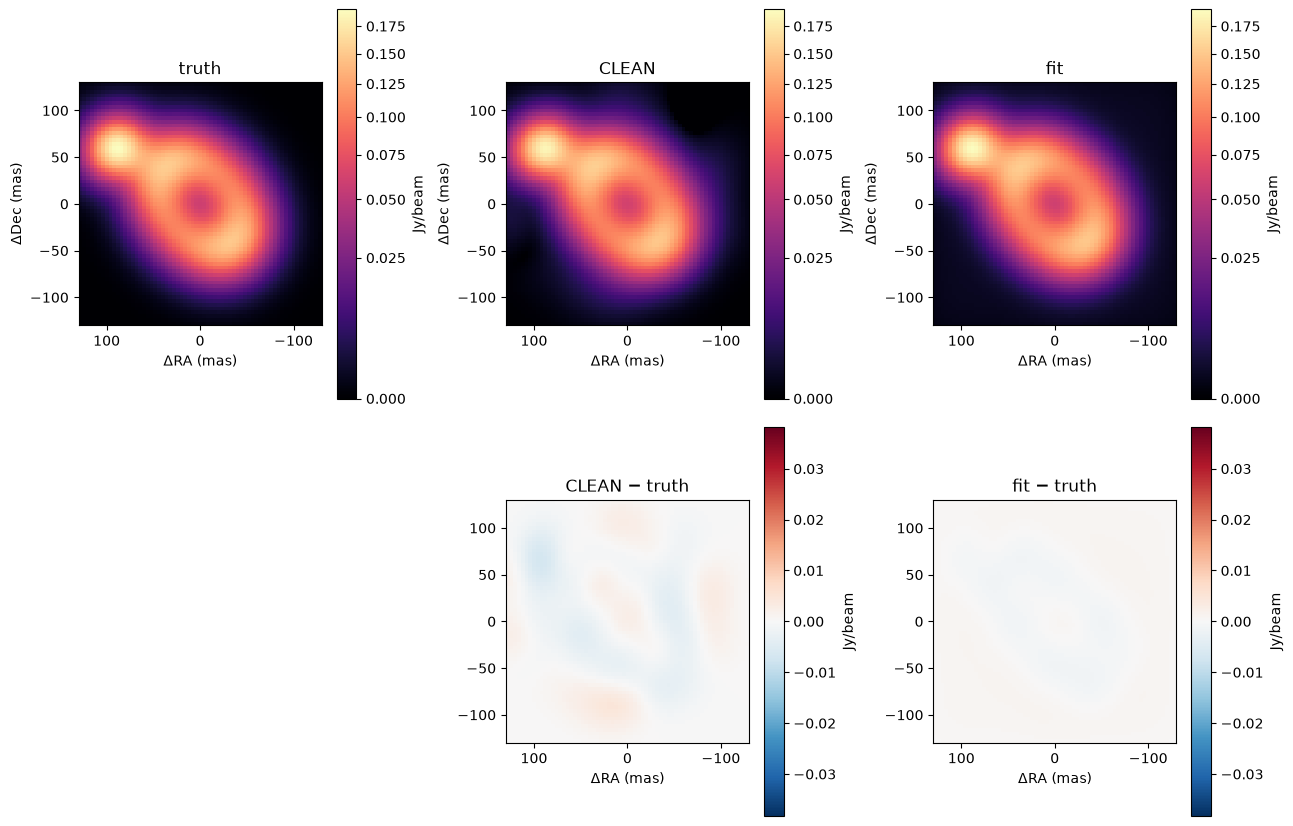

In [8]:
beam = res.beam
zeros = onp.zeros((N, N))
fit_image = onp.asarray(scene(result.values).brightness) * float(result.values["cal.flux"])
panels = {
    "truth": restore(truth, zeros, beam, S),
    "CLEAN": restore(res.model, zeros, beam, S),
    "fit": restore(fit_image, zeros, beam, S),
}
half = N * S / 2
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for ax, (name, im) in zip(axes[0], panels.items()):
    shown = ax.imshow(im, extent=[half, -half, -half, half], origin="upper", cmap="magma", norm=PowerNorm(0.5, vmin=0, vmax=panels["truth"].max()))
    ax.set(title=name, xlabel="ΔRA (mas)", ylabel="ΔDec (mas)")
    fig.colorbar(shown, ax=ax, label="Jy/beam")
lim = 0.2 * panels["truth"].max()
for ax, name in zip(axes[1, 1:], ("CLEAN", "fit")):
    shown = ax.imshow(panels[name] - panels["truth"], extent=[half, -half, -half, half], origin="upper", cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set(title=f"{name} − truth", xlabel="ΔRA (mas)")
    fig.colorbar(shown, ax=ax, label="Jy/beam")
axes[1, 0].axis("off")
fig.tight_layout()

## Diagnostics

The fit statistic is the raw χ² per datum on the quoted errors, `Σ w |V − M|² / (2N)` (two real numbers per visibility), which should be near 1 for a model that fits noise-limited data; it is not rescaled. We also report the flux and the rms difference from the truth through the beam, relative to the truth's peak.

In [9]:
w = onp.asarray(data.weight)
def chi2_per_datum(model_vis):
    return float(onp.sum(w * onp.abs(onp.asarray(data.vis) - model_vis) ** 2) / (2 * len(data)))

fit_vis = onp.asarray(data.model(scene(result.values), result.values, nuis))
peak = panels["truth"].max()
for name, model_vis, im, flux in (("CLEAN", res.model_visibilities(data), panels["CLEAN"], res.model.sum()),
                                  ("fit", fit_vis, panels["fit"], fit_image.sum())):
    print(f"{name:5s} χ²/N = {chi2_per_datum(onp.asarray(model_vis)):.3f}, flux {flux:.3f} Jy (true {truth.sum():.3f}), "
          f"rms − truth {onp.sqrt(onp.mean((im - panels['truth']) ** 2)) / peak:.3f} of peak")
print(f"fit reports χ² = {result.info['chi2'][0]:.0f} for {int(result.info['ndata'][0])} data")

CLEAN χ²/N = 1.047, flux 0.994 Jy (true 1.000), rms − truth 0.009 of peak
fit   χ²/N = 1.001, flux 1.009 Jy (true 1.000), rms − truth 0.004 of peak
fit reports χ² = 120063 for 120000 data


## Notes

The fit used the default exact path. Fitted phase-centre offsets would need `offsets="spread"` in `ComplexVisData.toeplitz`, an opt-in extension that is derived here, not published; antenna gains and a fitted spectral index fall back to the direct transform. The package is provisional, so details may change before it settles. See the [radio interferometry guide](radio_interferometry.md) for the model, the nuisances and the Toeplitz χ², and the [CLEAN guide](radio_clean.md) for `clean`.